In [8]:
!pip install requests
!pip install pandas
!pip install matplotlib
!pip install numpy
import requests
import pandas as pd
import io
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
TXT_LINK_X = "https://02427.compute.dtu.dk/material/exercises/lecture01_written_exercises/lecture01_kernel_methods_conditional_mean.txt"
# Download the x-values file from the provided link
response = requests.get(TXT_LINK_X)
df_x = pd.read_csv(io.StringIO(response.text), sep="\t", header=None, names=["x"])

In [6]:
TXT_LINK_Y = "https://02427.compute.dtu.dk/material/exercises/lecture01_written_exercises/lecture01_kernel_methods_approximate_pdf.txt"

# Download the y-values file from the provided link
response = requests.get(TXT_LINK_Y)
df_y = pd.read_csv(io.StringIO(response.text), sep="\t", header=None, names=["y"])

print(pd.DataFrame(df_y).head())

          y
0  0.189757
1  0.302879
2  0.541262
3  0.277482
4  0.224909


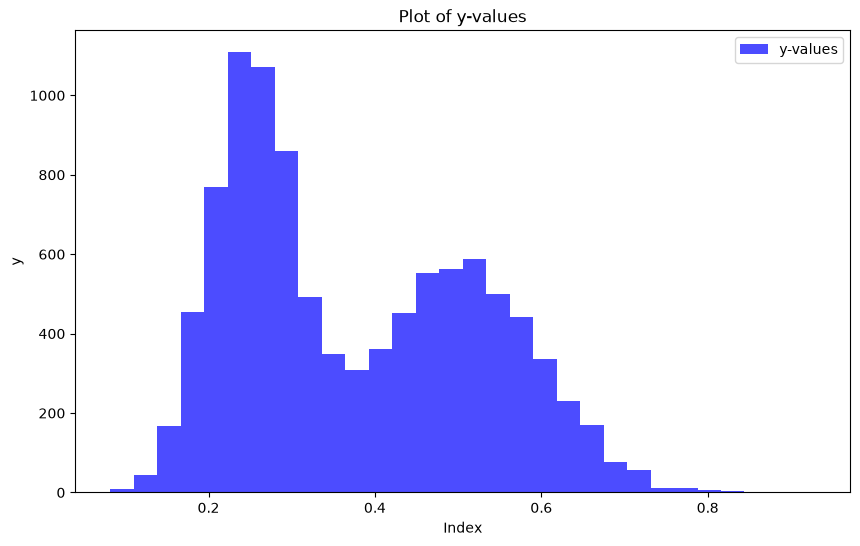

In [22]:
# Plot only y-values
plt.figure(figsize=(10, 6))
plt.hist(df_y['y'], label='y-values', color='blue', bins=30, alpha=0.7)
plt.title('Plot of y-values')
plt.xlabel('Index')
plt.ylabel('y')
plt.legend()

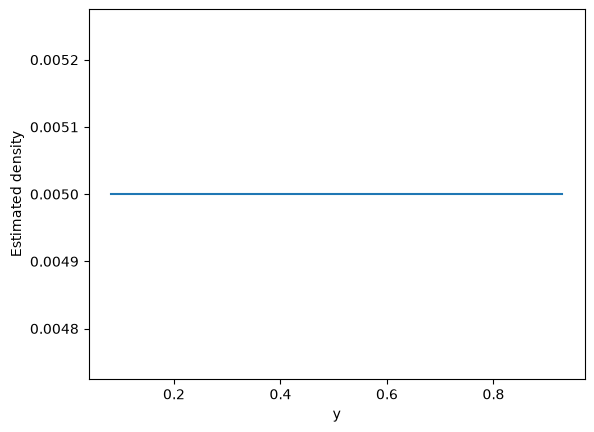

In [24]:
# Get the range min/max of the y-values
y_min = df_y["y"].min()
y_max = df_y["y"].max()


def indicator(Y_t, y, h):
    """
    χ_h(Y_t; y) =
        1, if y - h <= Y_t < y + h
        0, otherwise
    """
    if y - h <= Y_t < y + h:
        return 1
    return 0


def approximate_pdf(y, Y, h):
    """
    f(y) ≈ 1 / (2Nh) * sum_{t=1}^N χ_h(Y_t; y)
    """
    N = len(Y)

    return (1 / (2 * N * h)) * sum(
        indicator(Y_t, y, h)
        for Y_t in Y
    )


# Points where we want to estimate f(y)
y_values = np.linspace(y_min, y_max, 500)

h = 100

# Estimate f(y) separately for each y
pdf = [
    approximate_pdf(y, df_y["y"], h)
    for y in y_values
]


plt.plot(y_values, pdf)
plt.xlabel("y")
plt.ylabel("Estimated density")
plt.show()